Importing Libraries

In [34]:
# Data handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt

# Dataset loading
from sklearn.datasets import fetch_openml

# Data preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Model evaluation
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

# Artificial Neural Network
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.callbacks import EarlyStopping

# For reproducible results
import tensorflow as tf

np.random.seed(42)
tf.random.set_seed(42)

print("All libraries imported successfully!")

All libraries imported successfully!


Load the Boston Housing Dataset

In [35]:
# Load the dataset from OpenML
boston = fetch_openml(
    name="boston",
    version=1,
    as_frame=True
)

# Store input features in X
X = boston.data

# Store house prices in y
y = pd.to_numeric(boston.target)

print("Dataset loaded successfully!")
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Dataset loaded successfully!
Features shape: (506, 13)
Target shape: (506,)


Explore the dataset

In [36]:
# Display the first five rows
print(X.head())

# Display the column names
print("\nFeature names:")
print(X.columns.tolist())

# Display the dataset information
print("\nDataset information:")
print(X.info())

# Check missing values
print("\nMissing values:")
print(X.isnull().sum())

# Statistical summary
print("\nStatistical summary:")
print(X.describe())

# Display target values
print("\nFirst 5 house prices:")
print(y.head())

      CRIM    ZN  INDUS CHAS    NOX     RM   AGE     DIS RAD    TAX  PTRATIO  \
0  0.00632  18.0   2.31    0  0.538  6.575  65.2  4.0900   1  296.0     15.3   
1  0.02731   0.0   7.07    0  0.469  6.421  78.9  4.9671   2  242.0     17.8   
2  0.02729   0.0   7.07    0  0.469  7.185  61.1  4.9671   2  242.0     17.8   
3  0.03237   0.0   2.18    0  0.458  6.998  45.8  6.0622   3  222.0     18.7   
4  0.06905   0.0   2.18    0  0.458  7.147  54.2  6.0622   3  222.0     18.7   

        B  LSTAT  
0  396.90   4.98  
1  396.90   9.14  
2  392.83   4.03  
3  394.63   2.94  
4  396.90   5.33  

Feature names:
['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 13 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   CRIM     506 non-null    float64 
 1   ZN       506 non-null    float64 
 2   INDUS    506 n

Visualize house prices

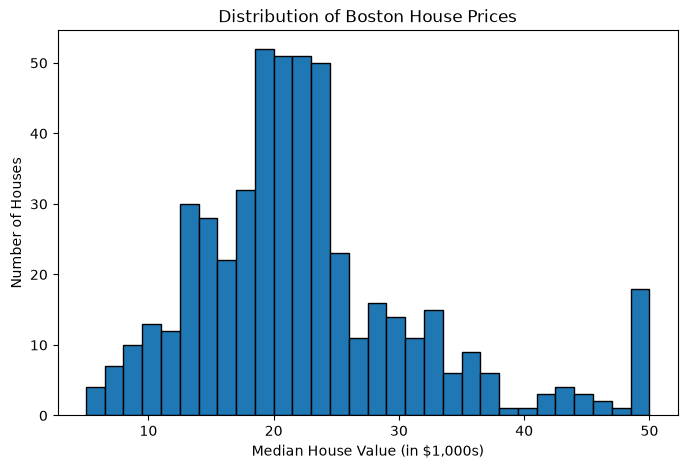

In [37]:
plt.figure(figsize=(8, 5))

plt.hist(y, bins=30, edgecolor="black")

plt.title("Distribution of Boston House Prices")
plt.xlabel("Median House Value (in $1,000s)")
plt.ylabel("Number of Houses")

plt.show()

Prepare the input and target variables

In [38]:
# Convert features and target into numeric arrays
X = X.apply(pd.to_numeric, errors="coerce")
y = pd.to_numeric(y, errors="coerce")

# Combine X and y to remove rows with missing values consistently
data = X.copy()
data["MEDV"] = y

data = data.dropna()

# Separate features and target again
X = data.drop(columns=["MEDV"])
y = data["MEDV"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (506, 13)
y shape: (506,)


Split the dataset

In [39]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

Training features: (404, 13)
Testing features: (102, 13)
Training targets: (404,)
Testing targets: (102,)


Scale the features

In [40]:
# Create the scaler
scaler = StandardScaler()

# Learn scaling parameters from training data
X_train_scaled = scaler.fit_transform(X_train)

# Apply the same scaling to test data
X_test_scaled = scaler.transform(X_test)

print("Training data scaled successfully!")
print("Testing data scaled successfully!")

Training data scaled successfully!
Testing data scaled successfully!


Build the ANN model

In [41]:
# Create the ANN
model = Sequential([
    # Input layer: 13 features
    Input(shape=(X_train_scaled.shape[1],)),

    # First hidden layer
    Dense(64, activation="relu"),

    # Second hidden layer
    Dense(32, activation="relu"),

    # Output layer: one predicted price
    Dense(1)
])

# Display the model architecture
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                 │ (None, 64)             │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,009 (11.75 KB)

 Trainable params: 3,009 (11.75 KB)

 Non-trainable params: 0 (0.00 B)

Compile the ANN

In [42]:
model.compile(
    optimizer="adam",
    loss="mean_squared_error",
    metrics=["mae"]
)

print("ANN model compiled successfully!")

ANN model compiled successfully!


Train the ANN

In [43]:
# Stop early if validation loss does not improve
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True
)

# Train the model
history = model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.20,
    epochs=50,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - loss: 604.8769 - mae: 22.6191 - val_loss: 525.9529 - val_mae: 21.3214
Epoch 2/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 566.3159 - mae: 21.7036 - val_loss: 490.2862 - val_mae: 20.4264
Epoch 3/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 525.9231 - mae: 20.7084 - val_loss: 450.0169 - val_mae: 19.3859
Epoch 4/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 478.9781 - mae: 19.5513 - val_loss: 403.3981 - val_mae: 18.1357
Epoch 5/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 424.3644 - mae: 18.1930 - val_loss: 350.2515 - val_mae: 16.7075
Epoch 6/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 362.4406 - mae: 16.5960 - val_loss: 291.5589 - val_mae: 15.1047
Epoch 7/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 295.6548 - mae: 14.7038 - val_loss: 230.2588 - val_mae: 13.2223
Epoch 8/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 229.1520 - mae: 12.5794 - val_loss: 171.9085 - val_mae: 11.1166
Epoch 9/50
11/11

Plot the training and validation loss

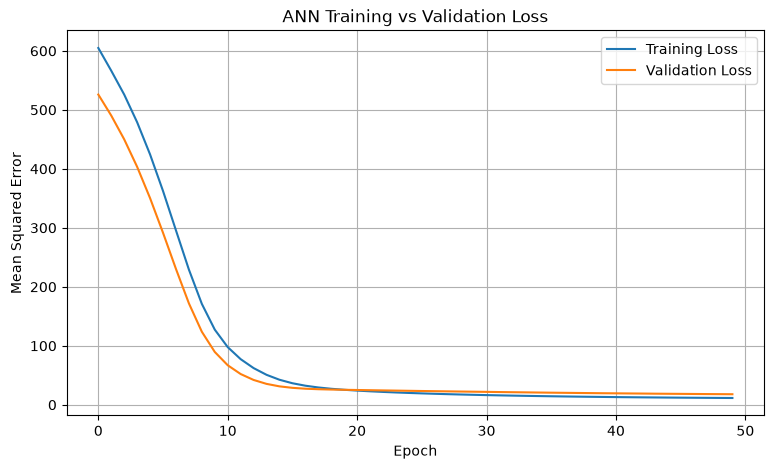

In [44]:
plt.figure(figsize=(9, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("ANN Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.grid(True)

plt.show()

Make predictions on test data

In [45]:
# Predict house prices
y_pred = model.predict(X_test_scaled)

# Convert predictions from 2D to 1D
y_pred = y_pred.flatten()

print("First 10 actual prices:")
print(y_test.iloc[:10].to_numpy())

print("\nFirst 10 predicted prices:")
print(y_pred[:10])

1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/stepWARNING:tensorflow:6 out of the last 13 calls to <function TensorFlowTrainer.make_predict_function.<locals>.one_step_on_data_distributed at 0x0000023C71D6F7E0> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
First 10 actual prices:
[23.6 32.4 13.6 22.8 16.1 20.  17.8 14.  19.6 16.8]

First 10 predicted prices:
[28.680109 31.17016  19.510859 27.731556 16.321035 20.533354 15.638051
 14.532277 23.739946 17

Evaluate the ANN

In [46]:
# Mean Absolute Error
mae = mean_absolute_error(y_test, y_pred)

# Mean Squared Error
mse = mean_squared_error(y_test, y_pred)

# Root Mean Squared Error
rmse = np.sqrt(mse)

# R-squared score
r2 = r2_score(y_test, y_pred)

print("ANN Model Evaluation")
print("--------------------")
print(f"MAE  : {mae:.4f}")
print(f"MSE  : {mse:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R²   : {r2:.4f}")

ANN Model Evaluation
--------------------
MAE  : 2.5066
MSE  : 15.2821
RMSE : 3.9092
R²   : 0.7916


Compare actual vs predicted prices

In [47]:
comparison = pd.DataFrame({
    "Actual Price ($1000s)": y_test.to_numpy(),
    "Predicted Price ($1000s)": y_pred
})

print(comparison.head(10).round(2))

   Actual Price ($1000s)  Predicted Price ($1000s)
0                   23.6                 28.680000
1                   32.4                 31.170000
2                   13.6                 19.510000
3                   22.8                 27.730000
4                   16.1                 16.320000
5                   20.0                 20.530001
6                   17.8                 15.640000
7                   14.0                 14.530000
8                   19.6                 23.740000
9                   16.8                 17.100000


Plot actual vs predicted prices

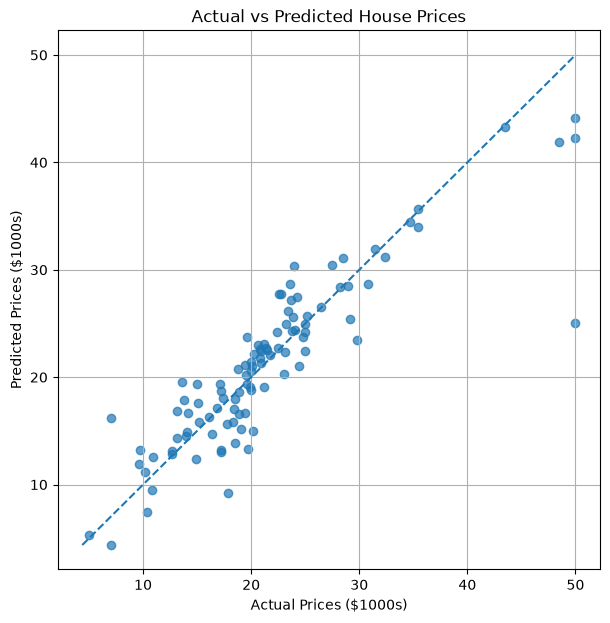

In [48]:
plt.figure(figsize=(7, 7))

plt.scatter(y_test, y_pred, alpha=0.7)

# Ideal prediction line
minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.title("Actual vs Predicted House Prices")
plt.xlabel("Actual Prices ($1000s)")
plt.ylabel("Predicted Prices ($1000s)")
plt.grid(True)

plt.show()

Plot prediction errors

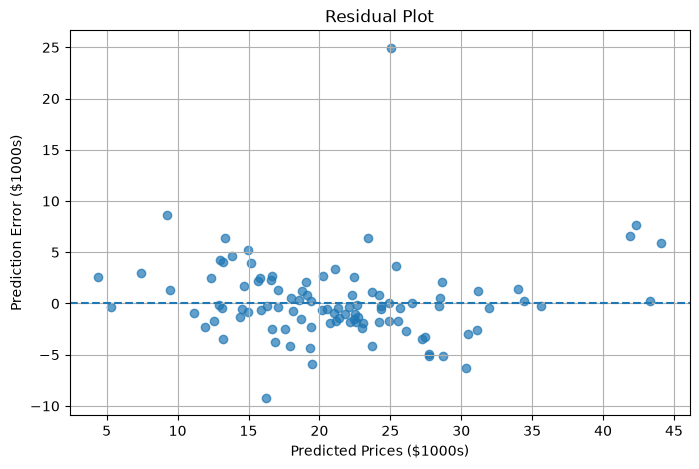

In [49]:
# Calculate residuals
errors = y_test.to_numpy() - y_pred

plt.figure(figsize=(8, 5))

plt.scatter(y_pred, errors, alpha=0.7)
plt.axhline(y=0, linestyle="--")

plt.title("Residual Plot")
plt.xlabel("Predicted Prices ($1000s)")
plt.ylabel("Prediction Error ($1000s)")
plt.grid(True)

plt.show()

Predict the price of a new house

In [50]:
# Use one test example as an example of a new house
new_house = X_test.iloc[[0]]

# Scale the features using the already fitted scaler
new_house_scaled = scaler.transform(new_house)

# Predict the house price
predicted_price = model.predict(new_house_scaled, verbose=0)[0, 0]

print(f"Predicted house price: ${predicted_price * 1000:,.2f}")

Predicted house price: $28,680.11


Save the trained model

In [51]:
# Save the ANN model
model.save("boston_ann_model.keras")

print("Model saved successfully!")

Model saved successfully!
